# Portfolio met aandelen in R
We gaan kijken of we ook in R aandelendata kunnen inlezen en met deze data mooie grafieken (en andere bewerkingen) kunnen maken.<br>
https://blog.exploratory.io/introduction-to-tidyquant-quantitative-financial-analysis-for-tidyverse-habitats-e5f72a023ce2

Eerst wat huishoudelijke informatie:<br>
- Welke versie van R gebruiken we op dit moment?<br>
- Welke pakketten zijn er allemaal al geinstalleerd in de Colab-omgeving?

In [1]:
R.version.string

[1] "R version 4.4.2 (2024-10-31)"

In [2]:
print(installed.packages())

              Package         LibPath                         Version   
IRdisplay     "IRdisplay"     "/usr/local/lib/R/site-library" "1.1"     
IRkernel      "IRkernel"      "/usr/local/lib/R/site-library" "1.3.2"   
pbdZMQ        "pbdZMQ"        "/usr/local/lib/R/site-library" "0.3-13"  
repr          "repr"          "/usr/local/lib/R/site-library" "1.1.7"   
askpass       "askpass"       "/usr/lib/R/site-library"       "1.2.1"   
backports     "backports"     "/usr/lib/R/site-library"       "1.5.0"   
base64enc     "base64enc"     "/usr/lib/R/site-library"       "0.1-3"   
bit           "bit"           "/usr/lib/R/site-library"       "4.5.0.1" 
bit64         "bit64"         "/usr/lib/R/site-library"       "4.5.2"   
blob          "blob"          "/usr/lib/R/site-library"       "1.2.4"   
boot          "boot"          "/usr/lib/R/site-library"       "1.3-31"  
brew          "brew"          "/usr/lib/R/site-library"       "1.0-10"  
brio          "brio"          "/usr/lib/R/site-libr

Nu we dit weten, installeren we 1 pakket dat ontbreekt (tidyquant - dit duurt even ..) en lezen vervolgens de benodigde libraries (tidyverse en tidyquant) in:<br>
https://cran.r-project.org/web/packages/tidyquant/index.html

In [3]:
install.packages("tidyquant")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘globals’, ‘listenv’, ‘parallelly’, ‘mvtnorm’, ‘pcaPP’, ‘DEoptimR’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘furrr’, ‘crosstalk’, ‘warp’, ‘BH’, ‘fracdiff’, ‘lmtest’, ‘tseries’, ‘urca’, ‘RcppArmadillo’, ‘RcppRoll’, ‘future’, ‘quadprog’, ‘pyinit’, ‘rrcov’, ‘robustbase’, ‘recipes’, ‘rsample’, ‘plotly’, ‘padr’, ‘slider’, ‘anytime’, ‘forecast’, ‘tsfeatures’, ‘lazyeval’, ‘PerformanceAnalytics’, ‘RobStatTM’, ‘quantmod’, ‘timetk’, ‘timeDate’, ‘TTR’, ‘xts’, ‘zoo’




In [4]:
library(tidyverse)
library(tidyquant)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 

── Attaching core tidyquant packages ─────────────────────── tidyquant 1.0.10 ──
✔ PerformanceAnalytics 2.0.8      ✔ TTR                  0.24.4
✔ quantmod             0.4.26     ✔ xts                  0.14.1
── Conflicts ────────────────────────────────────────── tidyquant_conflicts() ──
✖ zoo::as.Date()                 masks base::as.Date()
✖ zoo::as.Date.numeric()        

## Data van 1 aandeel
We lezen, in de variabele aapl, koersdata in van het aandeel Apple met als begindatum 1 januari 2017 en als einddatum 1 januari 2025:

In [5]:
aapl <- tq_get('AAPL',
               from = "2017-01-01",
               to = "2025-01-01",
               get = "stock.prices")

Laatste 6 regels:

In [6]:
tail(aapl)

symbol,date,open,high,low,close,volume,adjusted
<chr>,<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAPL,2024-12-23,254.77,255.65,253.45,255.27,40858800,255.27
AAPL,2024-12-24,255.49,258.21,255.29,258.20,23234700,258.20
AAPL,2024-12-26,258.19,260.10,257.63,259.02,27237100,259.02
AAPL,2024-12-27,257.83,258.70,253.06,255.59,42355300,255.59
AAPL,2024-12-30,252.23,253.50,250.75,252.20,35557500,252.20
AAPL,2024-12-31,252.44,253.28,249.43,250.42,39480700,250.42


## Grafiek van 1 aandeel
We maken een lijngrafiek van de koers van Apple.<br>
Op de x-as zetten we de datum.<br>
Op de y-as zetten we de 'adjusted close'.<br>
De schaal op de y-as loopt van 0 tot 300, met sprongen van 10.

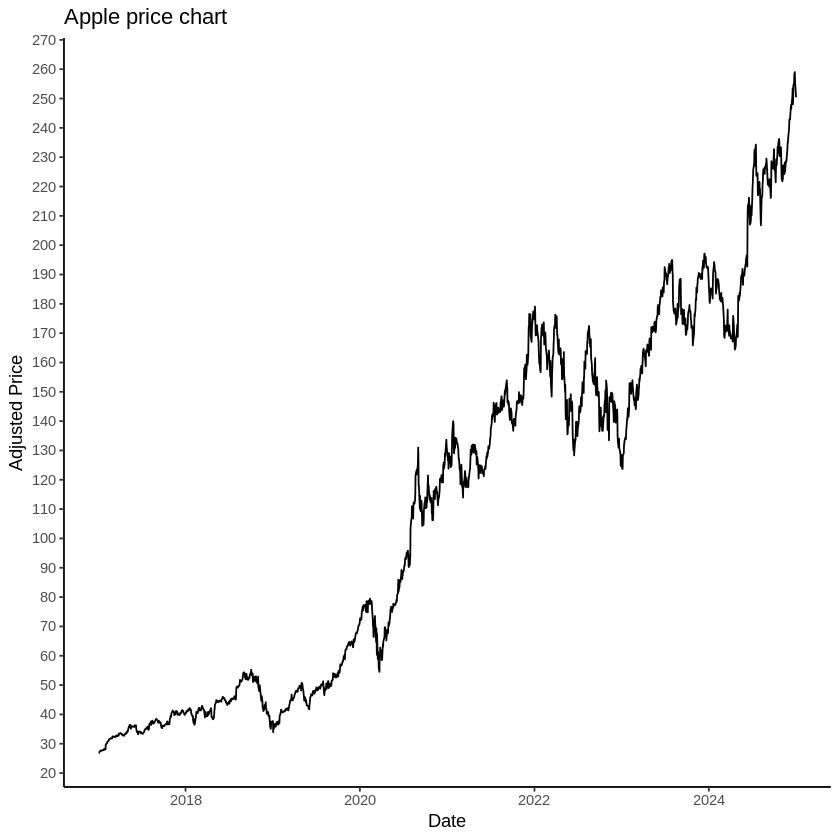

In [7]:
aapl %>%
  ggplot(aes(x = date, y = adjusted)) +
  geom_line() +
  theme_classic() +
  labs(x = 'Date',
       y = "Adjusted Price",
       title = "Apple price chart") +
  scale_y_continuous(breaks = seq(0,300,10))

## Data van meerdere aandelen = portfolio
We maken een lijstje met ticker-symbolen:<br>
- AAPL = Apple<br>
- NFLX = Netflix<br>
- AMZN = Amazone<br>
- MSFT = Microsoft<br>
- NVDA = Nvidia

In [8]:
tickers = c("AAPL", "NFLX", "AMZN", "MSFT", "NVDA")

We lezen de koersdata in in de variabele portfolio:

In [9]:
portfolio <- tq_get(tickers,
                 from = "2017-01-01",
                 to = "2025-1-1",
                 get = "stock.prices")

##Grafiek van portfolio
We maken een mooi grafiekje van deze portfolio:

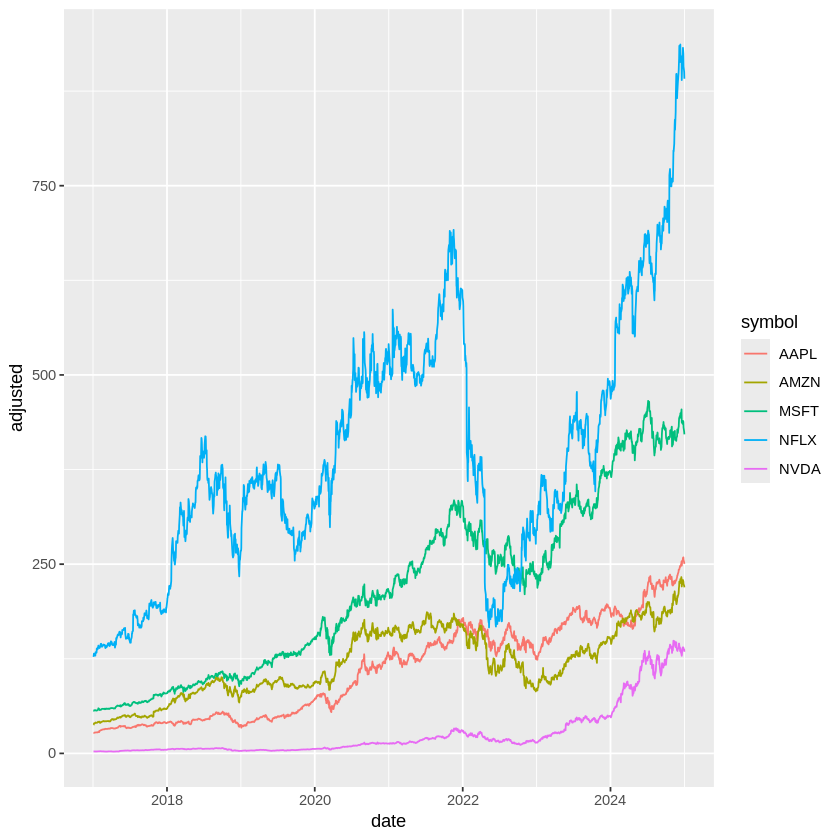

In [10]:
portfolio %>%
  ggplot(aes(x = date, y = adjusted, color = symbol)) +
  geom_line()

We willen graag grafieken van de afzonderlijke aandelen:

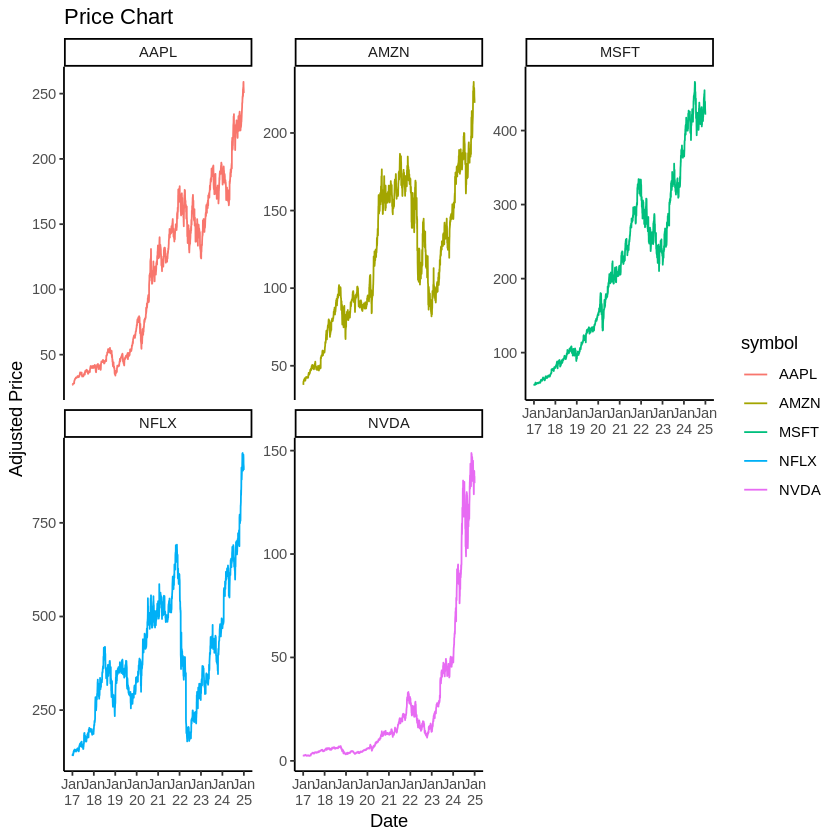

In [11]:
portfolio %>%
  ggplot(aes(x = date, y = adjusted, color = symbol)) +
  geom_line() +
  facet_wrap(~symbol,scales = 'free_y') +
  theme_classic() +
  labs(x = 'Date',
       y = "Adjusted Price",
       title = "Price Chart") +
  scale_x_date(date_breaks = "year",
               date_labels = "%b\n%y")

# Toetsvragen bij deze data<br>
- Bereken de gemiddelde koers van Apple in 2024<br>
- Bereken de standaardafwijking van het aandeel Nvidia voor de gehele periode<br>
- Maak voor de gehele periode een grafiek met daarin op de y-as het volume aan verhandelde aandelen Amazon.<br>

Toetsvraag: verzin zelf nog drie toetsvragen!<br>
https://quantdev.ssri.psu.edu/sites/qdev/files/tidyquant_tutorial_Gray.html


## Vraag 1 - Gemiddelde koers Apple

In [13]:
aapl_2024 <- tq_get('AAPL',
               from = "2024-01-01",
               to = "2025-1-1",
               get = "stock.prices")

In [14]:
head(aapl_2024)

symbol,date,open,high,low,close,volume,adjusted
<chr>,<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAPL,2024-01-02,187.15,188.44,183.89,185.64,82488700,184.7350
AAPL,2024-01-03,184.22,185.88,183.43,184.25,58414500,183.3518
AAPL,2024-01-04,182.15,183.09,180.88,181.91,71983600,181.0232
AAPL,2024-01-05,181.99,182.76,180.17,181.18,62303300,180.2967
AAPL,2024-01-08,182.09,185.60,181.50,185.56,59144500,184.6554
AAPL,2024-01-09,183.92,185.15,182.73,185.14,42841800,184.2374


In [17]:
price <- select(aapl_2024,adjusted)
mean(price)

Warning message in mean.default(price):
“argument is not numeric or logical: returning NA”


[1] NA

The warning "argument is not numeric or logical: returning NA" arises because the mean() function in R expects a numeric or logical vector as input. In this case, the price object might not be in the correct format.
<p>
Here's a breakdown of the problem and the solution:

**Problem:**<br>
The price object is created using select(aapl_2024, adjusted), which likely results in a tibble or data frame. The mean() function doesn't directly work on these data structures. It needs a numeric vector.

**Solution:**<br>
You need to extract the adjusted column as a numeric vector before applying the mean() function. You can achieve this using the $ operator or [[ operator.

In [18]:
price <- aapl_2024$adjusted # Or price <- aapl_2024[["adjusted"]]
mean(price, na.rm = TRUE)

[1] 206.7701

Andere oplossing is via summarise:

In [19]:
summarise(aapl_2024, gemiddelde_koers = mean(adjusted, na.rm = TRUE))

gemiddelde_koers
<dbl>
206.7701


## Vraag 2 - Standaardafwijking aandeel Nvidia

In [20]:
nvidia <- filter(portfolio, symbol=="NVDA")
summarise(nvidia, standaardafwijking = sd(adjusted, na.rm = TRUE))

standaardafwijking
<dbl>
34.39297


## Vraag 3 - Grafiek verhandeld volume Amazon

In [21]:
amazon <- tq_get('AMZN',
               from = "2017-01-01",
               to = "2025-01-1",
               get = "stock.prices")

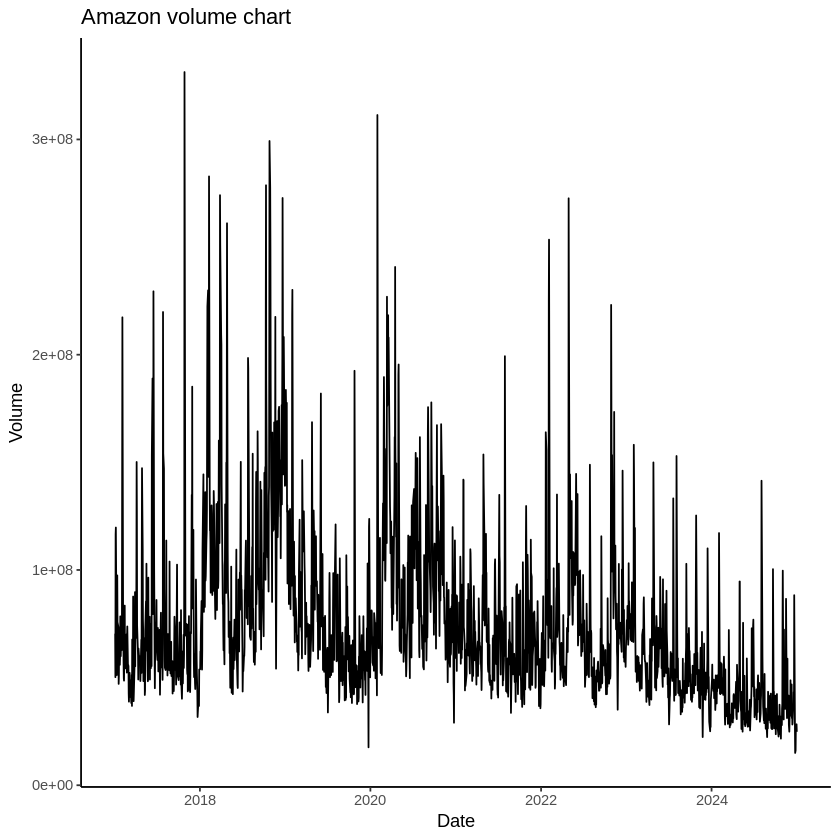

In [22]:
amazon %>%
  ggplot(aes(x = date, y = volume)) +
  geom_line() +
  theme_classic() +
  labs(x = 'Date',
       y = "Volume",
       title = "Amazon volume chart")+
  scale_y_continuous(breaks = seq(0,350000000,100000000))

Voor de liefhebber: maak nu alle werkplaatsopdrachten van blok 1 en 2 in R ... ;)